<a href="https://colab.research.google.com/github/TBDA-Classes/2026G3/blob/main/TBDA_P9_Outdoor_Weather_vs_HVAC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# P9 – Outdoor weather effect on HVAC (F5.3)
Zone: NW (then SE) Years: 2021–2022 · Data: cedint_f1_hourly_clean v0.3 + Open-Meteo archive

SyntaxError: invalid character '–' (U+2013) (311402251.py, line 2)

In [8]:
import pandas as pd

df = pd.read_csv("cedint_f1_hourly_clean.csv.gz")
df["timestamp_local"] = pd.to_datetime(df["timestamp_local"])
print("Dimensions:", df.shape)
df.head()

/tmp/ipykernel_647/744910305.py:3: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("cedint_f1_hourly_clean.csv.gz")


Dimensions: (470680, 50)


,timestamp_utc,timestamp_local,zone,zone_code,load_type,n_devices,era,recommendation,usable_for_model,energy_wh_model,...,flag_temp_extreme,flag_hum_invalid,flag_lum_day_zero,series_excluded,n_zero_record,n_partial,n_reset,n_spike,n_neg_noise,n_neg_large
0,2020-04-02 23:00:00,2020-04-03 01:00:00,NE,1NE,HVAC,2,hourly,Use,1,3.841,...,0.0,0.0,0.0,0,0,0,0,0,0,0
1,2020-04-03 00:00:00,2020-04-03 02:00:00,NE,1NE,HVAC,2,hourly,Use,1,3.763,...,0.0,0.0,0.0,0,0,0,0,0,0,0
2,2020-04-03 01:00:00,2020-04-03 03:00:00,NE,1NE,HVAC,2,hourly,Use,1,3.683,...,0.0,0.0,0.0,0,0,0,0,0,0,0
3,2020-04-03 02:00:00,2020-04-03 04:00:00,NE,1NE,HVAC,2,hourly,Use,1,3.720,...,0.0,0.0,0.0,0,0,0,0,0,0,0
4,2020-04-03 03:00:00,2020-04-03 05:00:00,NE,1NE,HVAC,2,hourly,Use,1,3.775,...,0.0,0.0,0.0,0,0,0,0,0,0,0


In [9]:
import requests

url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 40.404, "longitude": -3.839,   # CeDInt, Getafe — adjust if needed
    "start_date": "2020-01-01", "end_date": "2025-12-31",
    "hourly": "temperature_2m",
    "timezone": "Europe/Madrid",
}
meteo = pd.DataFrame(requests.get(url, params=params).json()["hourly"])
meteo["timestamp_local"] = pd.to_datetime(meteo["time"])
meteo = meteo.rename(columns={"temperature_2m": "temp_out_c"})[["timestamp_local", "temp_out_c"]]
print("Weather dimensions:", meteo.shape)
meteo.head()

Weather dimensions: (52608, 2)


,timestamp_local,temp_out_c
0,2020-01-01 00:00:00,2.7
1,2020-01-01 01:00:00,1.7
2,2020-01-01 02:00:00,1.6
3,2020-01-01 03:00:00,0.5
4,2020-01-01 04:00:00,0.3


In [10]:
df = df.merge(meteo, on="timestamp_local", how="left")
print("Rows without weather:", df["temp_out_c"].isna().sum())

Rows without weather: 0


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

zone = "NW"
hvac = df[
    (df["zone"] == zone) & (df["load_type"] == "HVAC") &
    (df["timestamp_local"].dt.year.isin([2021, 2022])) &
    (df["usable_for_model"] == 1)
].dropna(subset=["temp_out_c", "energy_wh_model"]).copy()

hvac["dh_cool"] = (hvac["temp_out_c"] - 22).clip(lower=0)   # cooling degree-hours
hvac["dh_heat"] = (18 - hvac["temp_out_c"]).clip(lower=0)   # heating degree-hours

print(f"Zone {zone} – number of hours analysed:", len(hvac))
for col in ["temp_out_c", "dh_cool", "dh_heat"]:
    r = hvac["energy_wh_model"].corr(hvac[col])
    rs = hvac["energy_wh_model"].corr(hvac[col], method="spearman")
    print(f"{col:12s}  Pearson={r:+.3f}  Spearman={rs:+.3f}")

Zone NW – number of hours analysed: 15985
temp_out_c    Pearson=+0.210  Spearman=-0.052
dh_cool       Pearson=+0.312  Spearman=+0.114
dh_heat       Pearson=-0.080  Spearman=+0.095


       pearson
lag_h         
0        0.210
1        0.204
2        0.198
3        0.193
4        0.189
5        0.185
6        0.182


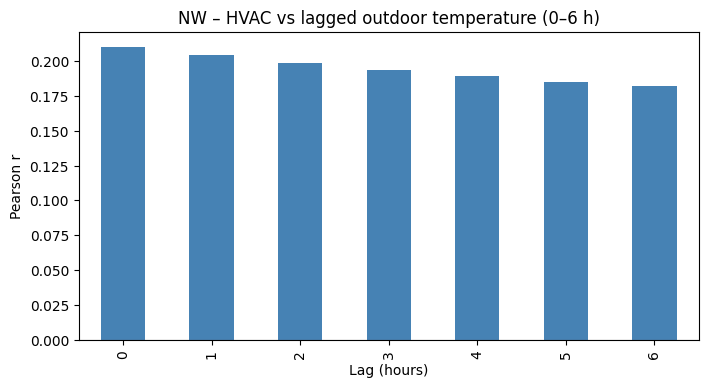

In [12]:
results = []
for lag in range(7):
    r = hvac["energy_wh_model"].corr(hvac["temp_out_c"].shift(lag))
    results.append({"lag_h": lag, "pearson": r})
lags = pd.DataFrame(results).set_index("lag_h")
print(lags.round(3))

lags.plot(kind="bar", legend=False, figsize=(8, 4), color="steelblue")
plt.title(f"{zone} – HVAC vs lagged outdoor temperature (0–6 h)")
plt.xlabel("Lag (hours)")
plt.ylabel("Pearson r")
plt.axhline(0, color="grey", linewidth=0.8)
plt.show()

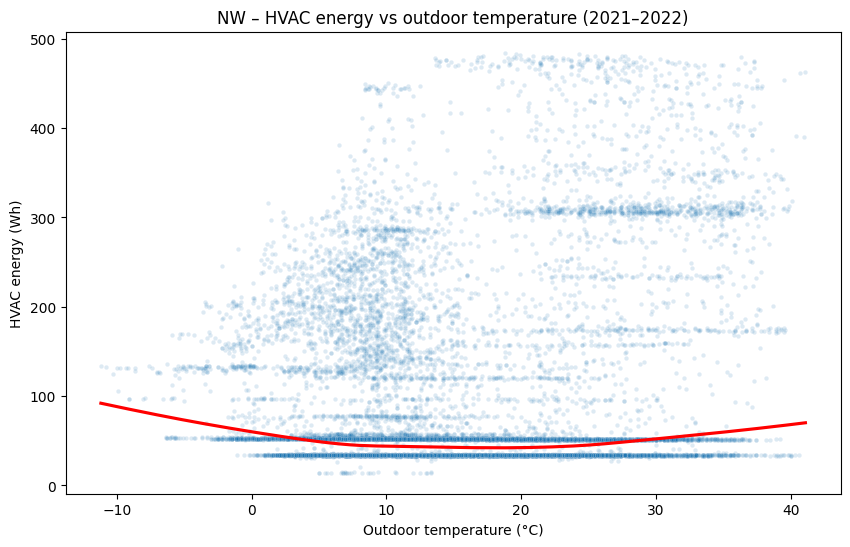

In [13]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=hvac, x="temp_out_c", y="energy_wh_model", alpha=0.15, s=10)
sns.regplot(data=hvac, x="temp_out_c", y="energy_wh_model",
            lowess=True, scatter=False, color="red")
plt.title(f"{zone} – HVAC energy vs outdoor temperature (2021–2022)")
plt.xlabel("Outdoor temperature (°C)")
plt.ylabel("HVAC energy (Wh)")
plt.show()

         mean  count
dh_bin              
0-1      97.0    441
1-3     103.3    772
3-5     127.1    617
5-8     142.3    732
8-12    166.0    681
>12     217.2    470


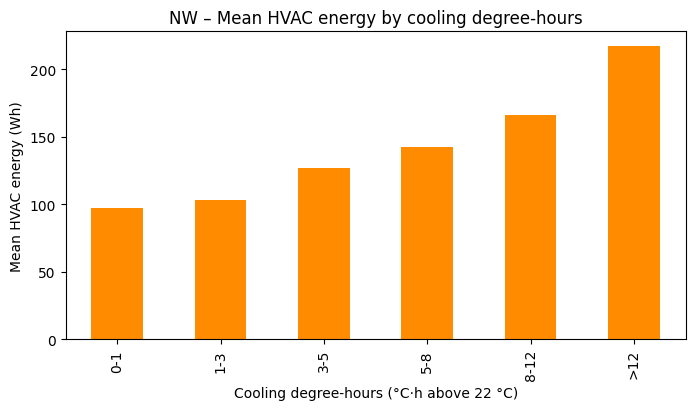

In [14]:
hvac["dh_bin"] = pd.cut(hvac["dh_cool"], bins=[0, 1, 3, 5, 8, 12, 100],
                        labels=["0-1", "1-3", "3-5", "5-8", "8-12", ">12"])
averages = hvac.groupby("dh_bin", observed=True)["energy_wh_model"].agg(["mean", "count"])
print(averages.round(1))

averages["mean"].plot(kind="bar", figsize=(8, 4), color="darkorange")
plt.title(f"{zone} – Mean HVAC energy by cooling degree-hours")
plt.xlabel("Cooling degree-hours (°C·h above 22 °C)")
plt.ylabel("Mean HVAC energy (Wh)")
plt.show()

In [15]:

import matplotlib.pyplot as plt
import seaborn as sns
zone = "SE"

hvac = df[
    (df["zone"] == zone) & (df["load_type"] == "HVAC") &
    (df["timestamp_local"].dt.year.isin([2021, 2022])) &
    (df["usable_for_model"] == 1)
].dropna(subset=["temp_out_c", "energy_wh_model"]).copy()

hvac["dh_cool"] = (hvac["temp_out_c"] - 22).clip(lower=0)   # cooling degree-hours
hvac["dh_heat"] = (18 - hvac["temp_out_c"]).clip(lower=0)   # heating degree-hours

print(f"Zone {zone} – number of hours analysed:", len(hvac))
for col in ["temp_out_c", "dh_cool", "dh_heat"]:
    r = hvac["energy_wh_model"].corr(hvac[col])
    rs = hvac["energy_wh_model"].corr(hvac[col], method="spearman")
    print(f"{col:12s}  Pearson={r:+.3f}  Spearman={rs:+.3f}")

Zone SE – number of hours analysed: 15782
temp_out_c    Pearson=-0.124  Spearman=-0.359
dh_cool       Pearson=+0.000  Spearman=-0.271
dh_heat       Pearson=+0.161  Spearman=+0.362


       pearson
lag_h         
0       -0.124
1       -0.156
2       -0.187
3       -0.213
4       -0.232
5       -0.244
6       -0.248


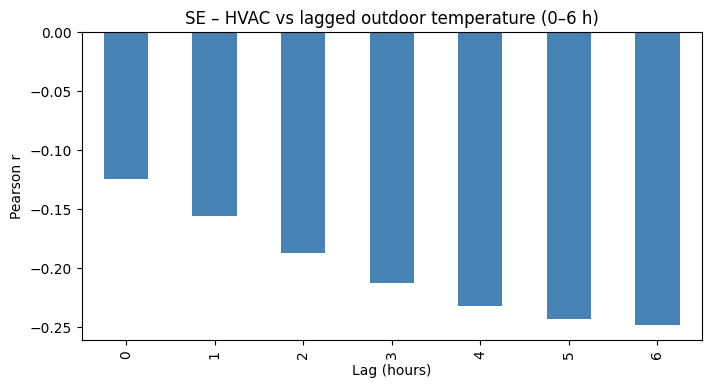

In [16]:
results = []
for lag in range(7):
    r = hvac["energy_wh_model"].corr(hvac["temp_out_c"].shift(lag))
    results.append({"lag_h": lag, "pearson": r})
lags = pd.DataFrame(results).set_index("lag_h")
print(lags.round(3))

lags.plot(kind="bar", legend=False, figsize=(8, 4), color="steelblue")
plt.title(f"{zone} – HVAC vs lagged outdoor temperature (0–6 h)")
plt.xlabel("Lag (hours)")
plt.ylabel("Pearson r")
plt.axhline(0, color="grey", linewidth=0.8)
plt.show()

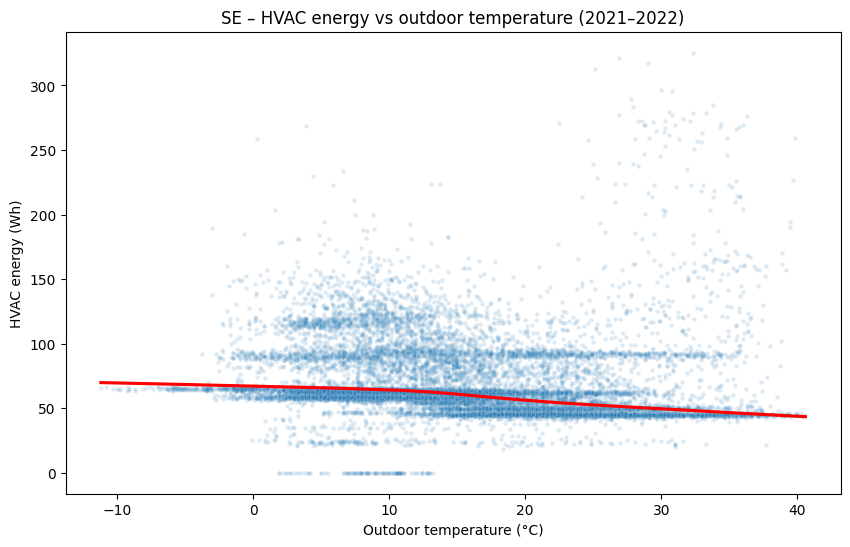

In [17]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=hvac, x="temp_out_c", y="energy_wh_model", alpha=0.15, s=10)
sns.regplot(data=hvac, x="temp_out_c", y="energy_wh_model",
            lowess=True, scatter=False, color="red")
plt.title(f"{zone} – HVAC energy vs outdoor temperature (2021–2022)")
plt.xlabel("Outdoor temperature (°C)")
plt.ylabel("HVAC energy (Wh)")
plt.show()

        mean  count
dh_bin             
0-1     60.0    440
1-3     58.9    783
3-5     60.2    620
5-8     65.0    716
8-12    71.5    635
>12     75.4    383


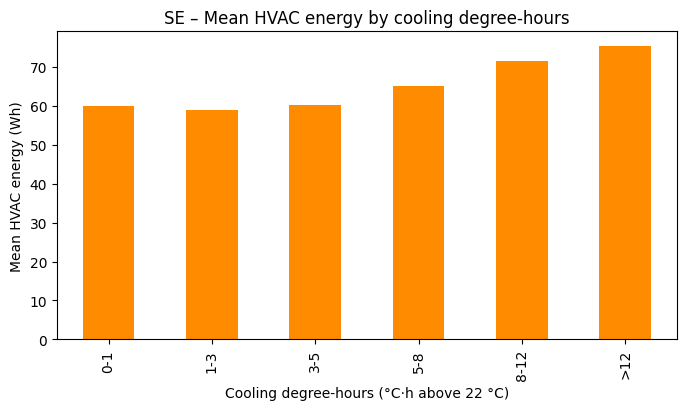

In [18]:
hvac["dh_bin"] = pd.cut(hvac["dh_cool"], bins=[0, 1, 3, 5, 8, 12, 100],
                        labels=["0-1", "1-3", "3-5", "5-8", "8-12", ">12"])
averages = hvac.groupby("dh_bin", observed=True)["energy_wh_model"].agg(["mean", "count"])
print(averages.round(1))

averages["mean"].plot(kind="bar", figsize=(8, 4), color="darkorange")
plt.title(f"{zone} – Mean HVAC energy by cooling degree-hours")
plt.xlabel("Cooling degree-hours (°C·h above 22 °C)")
plt.ylabel("Mean HVAC energy (Wh)")
plt.show()

# P9 – Outdoor weather effect on HVAC (F5.3)

## Objective
Quantify the effect of outdoor temperature and degree-hours on HVAC consumption, and identify the delayed response (0–6 h), in zones NW and SE of floor 1, years 2021–2022. The goal is to determine whether HVAC consumption can be anticipated from the weather forecast.

## Methodology
Hourly HVAC energy from the clean dataset (`cedint_f1_hourly_clean.csv.gz`, `usable_for_model = 1`, years 2021–2022) joined with hourly outdoor temperature from the Open-Meteo Archive API (site coordinates, timezone Europe/Madrid). Pearson and Spearman correlations were computed for three weather variables: raw outdoor temperature, cooling degree-hours (above 22 °C) and heating degree-hours (below 18 °C). Cross-correlations with lags of 0 to 6 hours, scatter plots with LOWESS smoothing, and mean consumption by degree-hour bins complete the analysis.

## Results
**Zone NW (15,985 hours analysed)**
- Outdoor temperature: Pearson +0.210, Spearman −0.052.
- Cooling degree-hours: Pearson +0.312, Spearman +0.114 — the strongest driver.
- Heating degree-hours: Pearson −0.080, Spearman +0.095 — no meaningful relationship.
- The scatter plot confirms a U-shaped relationship: high consumption at both temperature extremes, minimum around 10–15 °C.
- Mean HVAC energy rises from ~97 Wh to ~217 Wh (+124 %) between the lowest and highest cooling degree-hour bins.
- Lag analysis: the correlation is strongest at lag 0 (r = 0.210) and decays monotonically (0.204, 0.198, 0.193, 0.189, 0.185, 0.182) — an immediate response.

**Zone SE (15,782 hours analysed)**
- Outdoor temperature: Pearson −0.124, Spearman −0.359 — a negative, nearly monotonic relationship.
- Heating degree-hours: Pearson +0.161, Spearman +0.362 — the strongest driver.
- Cooling degree-hours: Pearson 0.000, Spearman −0.271 — no linear relationship.
- The scatter plot shows a downward-sloping trend, with no visible cooling branch.
- Mean HVAC energy rises only from ~60 Wh to ~75 Wh (+25 %) across cooling degree-hour bins.
- Lag analysis: the correlation grows in magnitude with the lag (−0.124 at lag 0 to −0.248 at lag 6) and has not yet peaked — a delayed response.

## Interpretation
Outdoor weather has a clear influence on HVAC consumption, but the two zones operate in opposite regimes: **NW is cooling-dominated** (driven by cooling degree-hours, +0.312) while **SE is heating-dominated** (driven by heating degree-hours, Spearman +0.362). The contrast between the NW U-shaped curve and the SE downward curve provides first evidence of a spatial difference between zones, which could be explained by the orientation of the building — the SE zone receives direct solar gains in the morning and midday, reducing summer cooling needs — although this hypothesis cannot be confirmed with the available data.

Degree-hours are better explanatory variables than raw outdoor temperature because they separate the heating and cooling regimes that raw temperature mixes.

The temporal behaviours also differ: NW responds immediately to outdoor temperature (strongest at lag 0), while SE responds with a delay (correlation still increasing at lag 6, consistent with the thermal inertia of the building in heating mode). Testing lags up to 12–24 h for SE is a recommended extension.

**Consequences for the forecast models (F1.2, F1.4):**
1. HVAC consumption can be anticipated from weather forecasts.
2. Weather variables must be selected per zone: cooling degree-hours for NW, heating degree-hours for SE.
3. The current outdoor temperature should be used as an exogenous variable for NW, while a lagged outdoor temperature is more informative for SE.

## Limitations
- These are correlations, not causal effects: occupancy and the daily schedule co-vary with outdoor temperature (the hottest hours are daytime hours) and are not controlled for here.
- The analysis covers 2021–2022 only; results may not generalise to 2025.
- The outdoor temperature comes from an external source (Open-Meteo Archive API), not from an on-site sensor, and is common to all zones.
- The lag analysis stops at 6 h; the SE delayed response may peak later.

## Source
Outdoor temperature: Open-Meteo Archive API (https://archive-api.open-meteo.com/v1/archive), hourly `temperature_2m`, coordinates of the CeDInt site, timezone Europe/Madrid, 2020–2025.